# fsaverage6 collision-group profile QC

This notebook summarizes existing collision-group metrics. Each row is one subject × hemisphere × fsaverage6 target vertex group; profile metrics use complete 21-point MD profiles.

In [ ]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/native_surface_analysis/collision_profile_analysis_pilot/shards')
files=sorted(ROOT.glob('D*/tables/collision_group_metrics.csv'))
metrics=pd.concat([pd.read_csv(p) for p in files],ignore_index=True)
print(f'subjects={metrics.subject_id.nunique():,}; groups={len(metrics):,}; files={len(files):,}')
metrics['multiplicity_label']=metrics.n_columns_mapped.map(lambda x:str(int(x)) if x<6 else '>=6')
display(metrics.head())

subjects=40; groups=3,035,665; files=40


,subject_id,hemisphere,source_region,target_vertex_id,n_columns_mapped,n_profiles_valid,multiplicity,multiplicity_label,native_region_count,majority_native_region,...,mixed_label,target_region,template_label_agreement_pct,valid_profile_label_agreement_pct,profile_pairs,profile_pearson_median,profile_mae_median,profile_rmse_median,native_anchor_distance_median,native_anchor_distance_max
0,D0007,lh,transversetemporal,12804,4,4,4,4,2,middletemporal,...,True,middletemporal,75.000000,75.000000,6,0.974626,0.000109,0.000129,0.942500,1.761615
1,D0007,lh,transversetemporal,38676,3,3,3,3,1,bankssts,...,False,middletemporal,0.000000,0.000000,3,0.991087,0.000078,0.000115,0.932443,0.957265
2,D0007,lh,transversetemporal,38677,3,3,3,3,2,middletemporal,...,True,middletemporal,66.666667,66.666667,3,0.993981,0.000165,0.000176,1.192608,1.380208
3,D0007,lh,transversetemporal,21136,5,5,5,5,1,bankssts,...,False,middletemporal,0.000000,0.000000,10,0.994182,0.000077,0.000095,0.955102,1.637418
4,D0007,lh,transversetemporal,9480,2,2,2,2,1,bankssts,...,False,middletemporal,0.000000,0.000000,1,0.980144,0.000199,0.000213,1.069037,1.069037


## 1. Multiplicity and denominator

Multiplicity percentages use covered fsaverage6 target vertices as the denominator. Uncovered vertices are not included here.

,multiplicity_label,covered_vertices,groups_with_2plus_valid_profiles,mixed_label_groups,covered_vertex_pct,profile_eligible_pct,mixed_label_pct
0,1,269553,0,0,8.88,0.00,0.00
1,2,897114,894770,25243,29.55,99.74,2.81
2,3,852395,848923,31057,28.08,99.59,3.64
3,4,564031,560621,22239,18.58,99.40,3.94
4,5,251133,249186,10831,8.27,99.22,4.31
5,>=6,201439,199635,9846,6.64,99.10,4.89


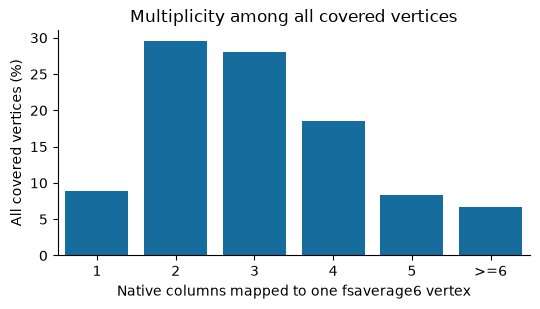

In [ ]:
group_counts=metrics.groupby('multiplicity_label',sort=False).agg(covered_vertices=('target_vertex_id','size'),groups_with_2plus_valid_profiles=('n_profiles_valid',lambda x:int((x>=2).sum())),mixed_label_groups=('mixed_label','sum')).reset_index()
labels=['1','2','3','4','5','>=6']
group_counts=group_counts.set_index('multiplicity_label').reindex(labels).reset_index()
group_counts['covered_vertex_pct']=100*group_counts['covered_vertices']/group_counts['covered_vertices'].sum()
group_counts['profile_eligible_pct']=100*group_counts['groups_with_2plus_valid_profiles']/group_counts['covered_vertices']
group_counts['mixed_label_pct']=100*group_counts['mixed_label_groups']/group_counts['covered_vertices']
display(group_counts.round(2))
fig,ax=plt.subplots(figsize=(5.5,3.2))
sns.barplot(data=group_counts,x='multiplicity_label',y='covered_vertex_pct',color='#0072B2',order=labels,ax=ax)
ax.set_xlabel('Native columns mapped to one fsaverage6 vertex')
ax.set_ylabel('All covered vertices (%)')
ax.set_title('Multiplicity among all covered vertices')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
plt.show()

,multiplicity_label,covered_vertices,covered_vertex_pct,conflict_vertex_pct,mixed_label_pct
0,2,897114,29.55,32.43,2.81
1,3,852395,28.08,30.82,3.64
2,4,564031,18.58,20.39,3.94
3,5,251133,8.27,9.08,4.31
4,>=6,201439,6.64,7.28,4.89


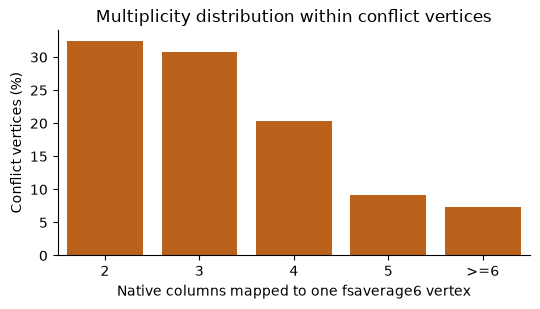

In [ ]:
conflict=group_counts[group_counts['multiplicity_label'].isin(['2','3','4','5','>=6'])].copy()
conflict_labels=['2','3','4','5','>=6']
conflict['conflict_vertex_pct']=100*conflict['covered_vertices']/conflict['covered_vertices'].sum()
conflict=conflict.set_index('multiplicity_label').reindex(conflict_labels).reset_index()
display(conflict[['multiplicity_label','covered_vertices','covered_vertex_pct','conflict_vertex_pct','mixed_label_pct']].round(2))
fig,ax=plt.subplots(figsize=(5.5,3.2))
sns.barplot(data=conflict,x='multiplicity_label',y='conflict_vertex_pct',color='#D55E00',order=conflict_labels,ax=ax)
ax.set_xlabel('Native columns mapped to one fsaverage6 vertex')
ax.set_ylabel('Conflict vertices (%)')
ax.set_title('Multiplicity distribution within conflict vertices')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
plt.show()

## 2. Profile similarity and native spatial span

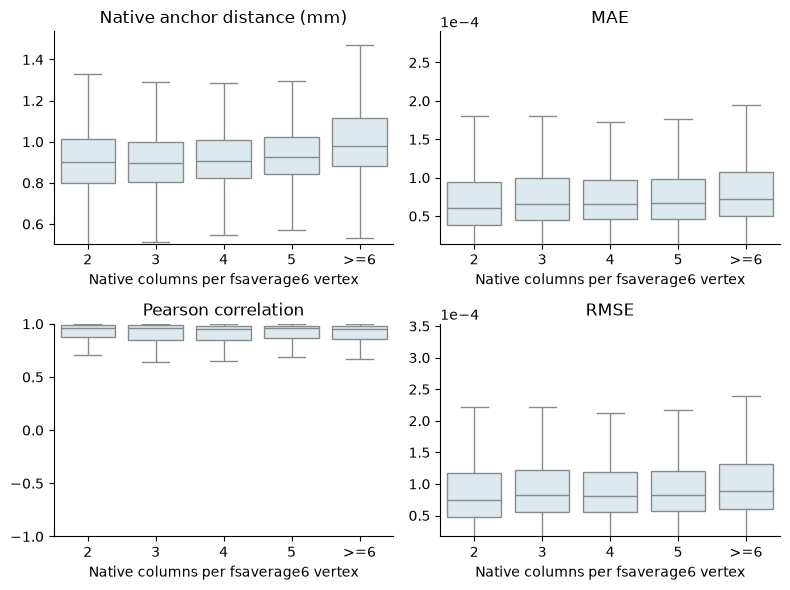

In [ ]:
eligible=metrics[metrics.n_profiles_valid>=2].copy()
plot_cols=['profile_pearson_median','profile_mae_median','profile_rmse_median','native_anchor_distance_median']
metric_labels={'profile_pearson_median':'Pearson correlation','profile_mae_median':'MAE','profile_rmse_median':'RMSE','native_anchor_distance_median':'Native anchor distance (mm)'}
long=eligible.melt(id_vars=['multiplicity_label'],value_vars=plot_cols,var_name='metric',value_name='value').dropna()
order=['2','3','4','5','>=6']
fig,axes=plt.subplots(2,2,figsize=(8,6)); axes=axes.ravel()
for ax,(name,g) in zip(axes, long.groupby('metric')):
    low,high=np.percentile(g.value,[1,99])
    sns.boxplot(data=g,x='multiplicity_label',y='value',order=order,showfliers=False,color='#D9EAF2',ax=ax)
    if name == 'profile_pearson_median':
        ax.set_ylim(-1, 1)
    else:
        ax.set_ylim(low, high)
    ax.set_title(metric_labels[name])
    ax.set_xlabel('Native columns per fsaverage6 vertex')
    ax.set_ylabel('')
    if name in ('profile_mae_median','profile_rmse_median'):
        ax.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
    ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Tail distributions

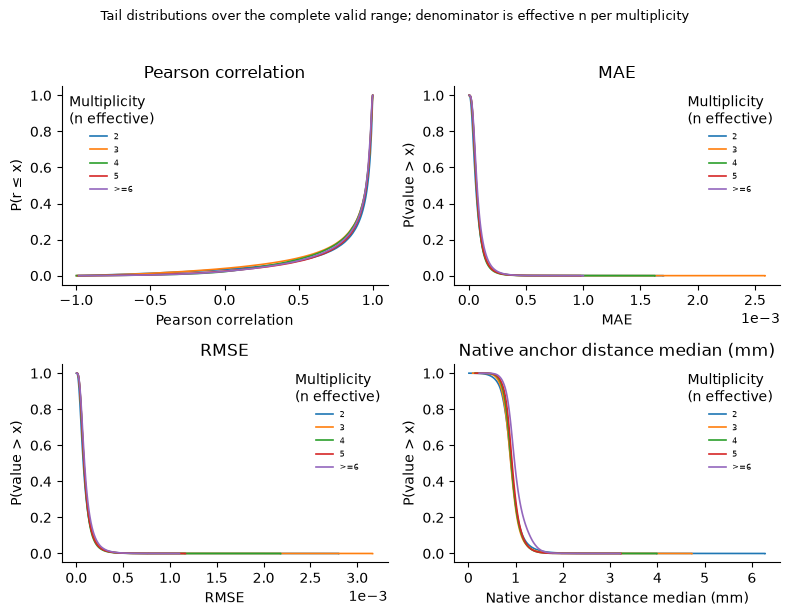

In [ ]:
tail_specs={'profile_pearson_median':('Pearson correlation',lambda x:np.mean(x<=x[:,None],axis=0) if False else None),'profile_mae_median':('MAE',None),'profile_rmse_median':('RMSE',None),'native_anchor_distance_median':('Native anchor distance median (mm)',None)}
fig,axes=plt.subplots(2,2,figsize=(8,6)); axes=axes.ravel()
for ax,(metric,(label,_)) in zip(axes,tail_specs.items()):
    for multiplicity in order:
        values=np.sort(eligible.loc[eligible.multiplicity_label.eq(multiplicity),metric].dropna().to_numpy())
        if not len(values): continue
        if metric=='profile_pearson_median':
            y=np.arange(1,len(values)+1)/len(values)
            ax.plot(values,y,label=multiplicity,linewidth=1.2)
            ax.set_ylabel('P(r ≤ x)')
        else:
            x=values
            y=1-np.arange(1,len(values)+1)/len(values)
            ax.step(x,y,where='post',label=multiplicity,linewidth=1.2)
            ax.set_ylabel('P(value > x)')
    ax.set_xlabel(label)
    ax.set_title(label)
    ax.legend(title='Multiplicity\n(n effective)',frameon=False,fontsize=6)
    if metric in ('profile_mae_median','profile_rmse_median'):
        ax.ticklabel_format(axis='x',style='sci',scilimits=(0,0))
    ax.spines[['top','right']].set_visible(False)
fig.suptitle('Tail distributions over the complete valid range; denominator is effective n per multiplicity',fontsize=9,y=1.02)
fig.tight_layout()
plt.show()

## 4. Subject-level summary

In [ ]:
subject_summary=metrics.groupby('subject_id').agg(collision_groups=('target_vertex_id','size'),groups_with_2plus_profiles=('n_profiles_valid',lambda x:int((x>=2).sum())),mixed_label_groups=('mixed_label','sum'),median_profile_r=('profile_pearson_median','median'),median_mae=('profile_mae_median','median'),median_rmse=('profile_rmse_median','median'),median_anchor_span=('native_anchor_distance_median','median')).reset_index()
subject_summary['eligible_group_pct']=100*subject_summary.groups_with_2plus_profiles/subject_summary.collision_groups
subject_summary['mixed_label_pct']=100*subject_summary.mixed_label_groups/subject_summary.collision_groups
display(subject_summary.round(4))

,subject_id,collision_groups,groups_with_2plus_profiles,mixed_label_groups,median_profile_r,median_mae,median_rmse,median_anchor_span,eligible_group_pct,mixed_label_pct
0,D0007,76060,68635,2426,0.9783,0.0001,0.0001,0.9120,90.2380,3.1896
1,D0029,76302,69633,2521,0.9726,0.0001,0.0001,0.9152,91.2597,3.3040
2,D0049,76278,70898,2615,0.9609,0.0001,0.0001,0.9102,92.9469,3.4282
3,D0050,76406,71521,2681,0.9406,0.0001,0.0001,0.9136,93.6065,3.5089
4,D0051,75705,65884,2272,0.9692,0.0001,0.0001,0.8978,87.0273,3.0011
5,D0052,75661,63685,2146,0.9538,0.0001,0.0001,0.8930,84.1715,2.8363
6,D0053,76295,72657,2785,0.9500,0.0001,0.0001,0.9347,95.2317,3.6503
7,D0057,76124,69330,2477,0.9534,0.0001,0.0001,0.9080,91.0751,3.2539
8,D0058,75857,66343,2301,0.9441,0.0001,0.0001,0.8973,87.4580,3.0333
9,D0059,75986,70493,2579,0.9505,0.0001,0.0001,0.9125,92.7710,3.3940


## 5. Label mixing

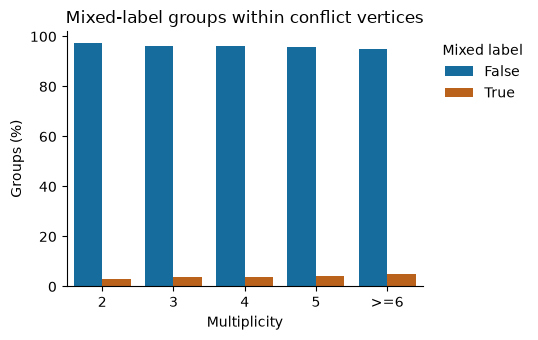

In [ ]:
conflict_metrics=metrics[metrics.n_columns_mapped>=2].copy()
conflict_order=['2','3','4','5','>=6']
plot=conflict_metrics.groupby(['multiplicity_label','mixed_label']).size().reset_index(name='groups')
plot['pct']=100*plot['groups']/plot.groupby('multiplicity_label')['groups'].transform('sum')
fig,ax=plt.subplots(figsize=(5.5,3.5))
sns.barplot(data=plot,x='multiplicity_label',y='pct',hue='mixed_label',order=conflict_order,palette={False:'#0072B2',True:'#D55E00'},ax=ax)
ax.set_xlabel('Multiplicity')
ax.set_ylabel('Groups (%)')
ax.set_title('Mixed-label groups within conflict vertices')
ax.legend(title='Mixed label',frameon=False,bbox_to_anchor=(1.02,1),loc='upper left')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Representative and tail groups

In [ ]:
eligible=metrics[metrics.n_profiles_valid>=2].copy()
small=eligible.nsmallest(10,'profile_mae_median')[['subject_id','hemisphere','source_region','target_vertex_id','n_columns_mapped','n_profiles_valid','profile_pearson_median','profile_mae_median','profile_rmse_median','native_anchor_distance_max','mixed_label']]
large=eligible.nlargest(10,'profile_mae_median')[['subject_id','hemisphere','source_region','target_vertex_id','n_columns_mapped','n_profiles_valid','profile_pearson_median','profile_mae_median','profile_rmse_median','native_anchor_distance_max','mixed_label']]
print('Smallest profile differences'); display(small.round(6)); print('Largest profile differences'); display(large.round(6))

Smallest profile differences


,subject_id,hemisphere,source_region,target_vertex_id,n_columns_mapped,n_profiles_valid,profile_pearson_median,profile_mae_median,profile_rmse_median,native_anchor_distance_max,mixed_label
2790775,D0091,rh,transversetemporal,16921,2,2,0.989573,0.000001,0.000001,0.588964,False
2027092,D0080,rh,transversetemporal,33307,2,2,0.999896,0.000001,0.000001,0.932116,False
276096,D0050,rh,transversetemporal,21001,2,2,0.999926,0.000001,0.000001,0.968049,False
1188818,D0065,rh,transversetemporal,5536,2,2,0.993390,0.000001,0.000002,0.854205,False
477638,D0053,lh,transversetemporal,8444,2,2,0.997165,0.000001,0.000002,0.746439,False
777236,D0060,lh,transversetemporal,29287,2,2,0.999979,0.000001,0.000002,0.655131,False
2182124,D0083,rh,transversetemporal,11855,2,2,0.989956,0.000001,0.000002,0.830301,False
801267,D0060,rh,transversetemporal,9890,2,2,0.999475,0.000002,0.000002,0.145891,False
1021138,D0063,rh,transversetemporal,32425,2,2,0.990285,0.000002,0.000003,0.810663,False
276044,D0050,rh,transversetemporal,12756,2,2,0.991912,0.000002,0.000002,1.008199,False


Largest profile differences


,subject_id,hemisphere,source_region,target_vertex_id,n_columns_mapped,n_profiles_valid,profile_pearson_median,profile_mae_median,profile_rmse_median,native_anchor_distance_max,mixed_label
617709,D0058,lh,transversetemporal,34387,3,3,-0.015638,0.002589,0.003165,1.421644,True
1488559,D0071,rh,transversetemporal,20213,3,3,0.741905,0.001776,0.001878,1.006014,False
2376542,D0086,lh,transversetemporal,2152,2,2,0.183575,0.001701,0.002172,0.742514,False
2018368,D0080,rh,transversetemporal,9424,2,2,0.703154,0.001656,0.002803,0.599830,False
1376174,D0070,lh,transversetemporal,6663,4,3,0.634861,0.001626,0.002183,1.148650,False
1098316,D0064,rh,transversetemporal,38577,3,3,-0.328362,0.001571,0.002561,1.311720,False
2018400,D0080,rh,transversetemporal,21002,2,2,0.916325,0.001544,0.002787,0.484206,False
1376156,D0070,lh,transversetemporal,30907,3,2,0.809917,0.001525,0.002187,0.912832,False
2376543,D0086,lh,transversetemporal,20403,2,2,0.488641,0.001500,0.001988,0.701709,False
1722584,D0075,rh,transversetemporal,27146,3,3,0.817983,0.001479,0.002133,0.897790,False


In [ ]:
id_cols=['subject_id','hemisphere','target_vertex_id','multiplicity_label','mixed_label','n_profiles_valid']
pearson_tail=eligible.nsmallest(20,'profile_pearson_median')[id_cols+['profile_pearson_median','profile_mae_median','profile_rmse_median','native_anchor_distance_median','native_anchor_distance_max']].assign(tail_type='lowest Pearson')
rmse_tail=eligible.nlargest(20,'profile_rmse_median')[id_cols+['profile_pearson_median','profile_mae_median','profile_rmse_median','native_anchor_distance_median','native_anchor_distance_max']].assign(tail_type='highest RMSE')
distance_tail=eligible.nlargest(20,'native_anchor_distance_max')[id_cols+['profile_pearson_median','profile_mae_median','profile_rmse_median','native_anchor_distance_median','native_anchor_distance_max']].assign(tail_type='maximum native anchor distance')
tail_groups=pd.concat([pearson_tail,rmse_tail,distance_tail],ignore_index=True)
tail_output=ROOT.parent/'tail_groups_to_review.csv'
tail_groups.to_csv(tail_output,index=False)
print('待检查尾部组：不自动排除，仅用于回溯检查')
print(f'Saved: {tail_output}')
display(tail_groups.round(6))

待检查尾部组：不自动排除，仅用于回溯检查
Saved: /mnt/newStor/paros/paros_WORK/xintong/results/native_surface_analysis/collision_profile_analysis_pilot/tail_groups_to_review.csv


,subject_id,hemisphere,target_vertex_id,multiplicity_label,mixed_label,n_profiles_valid,profile_pearson_median,profile_mae_median,profile_rmse_median,native_anchor_distance_median,native_anchor_distance_max,tail_type
0,D0084,lh,38515,2,False,2,-0.999232,0.000166,0.000282,1.294135,1.294135,lowest Pearson
1,D0058,lh,29719,3,False,3,-0.999166,0.000103,0.000103,0.858902,1.332405,lowest Pearson
2,D0091,rh,23608,2,False,2,-0.998981,0.000045,0.000060,1.529950,1.529950,lowest Pearson
3,D0062,lh,22660,4,False,4,-0.998726,0.000067,0.000068,1.256129,1.794353,lowest Pearson
4,D0007,rh,2286,2,False,2,-0.998515,0.000180,0.000204,1.769813,1.769813,lowest Pearson
5,D0076,lh,34405,2,False,2,-0.998190,0.000507,0.000685,0.820728,0.820728,lowest Pearson
6,D0051,rh,12496,2,False,2,-0.997674,0.000081,0.000089,0.985868,0.985868,lowest Pearson
7,D0074,rh,20954,2,False,2,-0.997512,0.000109,0.000153,0.715080,0.715080,lowest Pearson
8,D0057,lh,17892,2,False,2,-0.997496,0.000093,0.000108,1.192328,1.192328,lowest Pearson
9,D0089,lh,37315,3,False,3,-0.997302,0.000194,0.000215,0.877348,1.656068,lowest Pearson


## 7. Linking profile differences, spatial span, label mixing, and boundaries

,profile_pearson_median,profile_mae_median,profile_rmse_median,native_anchor_distance_median,native_anchor_distance_max
profile_pearson_median,1.000,-0.122,-0.148,-0.127,-0.123
profile_mae_median,-0.122,1.000,0.981,0.162,0.150
profile_rmse_median,-0.148,0.981,1.000,0.149,0.139
native_anchor_distance_median,-0.127,0.162,0.149,1.000,0.584
native_anchor_distance_max,-0.123,0.150,0.139,0.584,1.000


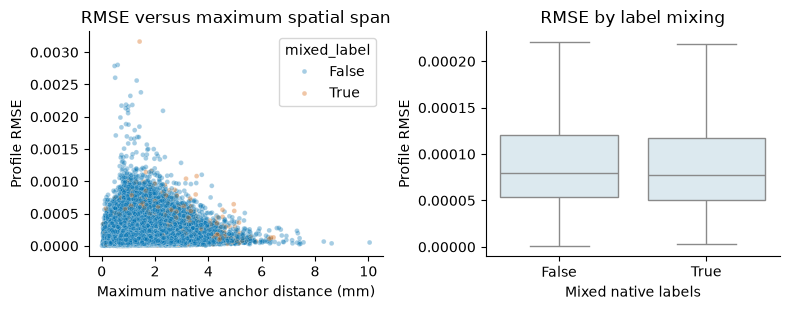

In [ ]:
eligible=metrics[metrics.n_profiles_valid>=2].copy()
relationship_cols=['profile_pearson_median','profile_mae_median','profile_rmse_median','native_anchor_distance_median','native_anchor_distance_max']
relationship_corr=eligible[relationship_cols].corr(method='spearman')
display(relationship_corr.round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.2))
sns.scatterplot(data=eligible,x='native_anchor_distance_max',y='profile_rmse_median',hue='mixed_label',palette={False:'#0072B2',True:'#D55E00'},alpha=.35,s=12,ax=axes[0])
axes[0].set_xlabel('Maximum native anchor distance (mm)')
axes[0].set_ylabel('Profile RMSE')
axes[0].set_title('RMSE versus maximum spatial span')
sns.boxplot(data=eligible,x='mixed_label',y='profile_rmse_median',showfliers=False,color='#D9EAF2',ax=axes[1])
axes[1].set_xlabel('Mixed native labels')
axes[1].set_ylabel('Profile RMSE')
axes[1].set_title('RMSE by label mixing')
for ax in axes: ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
plt.show()

In [ ]:
boundary_root=Path('/mnt/newStor/paros/paros_WORK/xintong/results/native_surface_analysis')
boundary_files=sorted(boundary_root.glob('boundary_disagreement_fsaverage6_D*/tables/boundary_agreement_summary.csv'))
if boundary_files:
    boundary=pd.concat([pd.read_csv(p) for p in boundary_files],ignore_index=True)
    boundary=boundary.rename(columns={'region':'source_region'})
    relation=eligible.merge(boundary[['subject_id','hemisphere','source_region','boundary_near_disagreement_pct','internal_disagreement_pct']],on=['subject_id','hemisphere','source_region'],how='left')
    display(relation[['profile_rmse_median','native_anchor_distance_max','boundary_near_disagreement_pct','internal_disagreement_pct']].corr(method='spearman').round(3))
    region_relation=relation.groupby('source_region').agg(profile_rmse=('profile_rmse_median','median'),max_span=('native_anchor_distance_max','median'),boundary_near_disagreement=('boundary_near_disagreement_pct','median'),internal_disagreement=('internal_disagreement_pct','median'),n_groups=('target_vertex_id','size')).sort_values('profile_rmse',ascending=False)
    display(region_relation.round(4))
else:
    print('No fsaverage6 boundary disagreement tables found.')

,profile_rmse_median,native_anchor_distance_max,boundary_near_disagreement_pct,internal_disagreement_pct
profile_rmse_median,1.000,0.139,0.030,0.024
native_anchor_distance_max,0.139,1.000,0.040,0.013
boundary_near_disagreement_pct,0.030,0.040,1.000,0.445
internal_disagreement_pct,0.024,0.013,0.445,1.000


,profile_rmse,max_span,boundary_near_disagreement,internal_disagreement,n_groups
source_region,,,,,
superiorfrontal,0.0001,1.2570,24.8956,0.1654,29495
transversetemporal,0.0001,1.1551,18.8192,0.0000,2723640


## Interpretation

Higher multiplicity indicates more native columns collapsed onto one template vertex. Correlation describes profile shape similarity, whereas MAE/RMSE describe absolute MD differences. Native anchor span measures spatial spread on the native white surface. Mixed-label groups indicate that multiple native anatomical labels contributed to the same template vertex. Boundary associations are region-level context unless group-specific boundary distances are computed. Display clipping only limits the plotted range; no groups are removed from the data or tail analyses.